(100, 2) (100,)


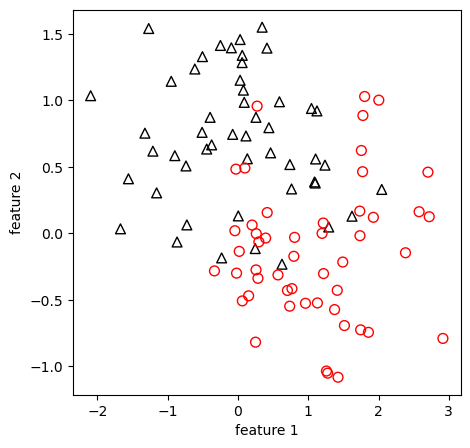

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression

N = 100
# setting random_state to a fixed value will make the output deterministic
X, y = make_moons(n_samples=N, noise=0.4, random_state=10)
print(X.shape, y.shape)

fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.scatter(X[y == 0, 0], X[y == 0, 1], color="k", marker="^", s=50, facecolors="none")
ax.scatter(X[y == 1, 0], X[y == 1, 1], color="r", marker="o", s=50, facecolors="none")
ax.set_xlabel("feature 1")
ax.set_ylabel("feature 2")
plt.show()

Scikit learn score: 0.85


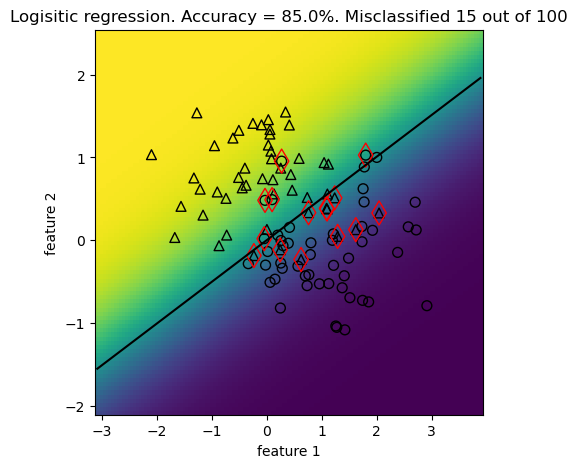

In [6]:
# logistic regression
clf = LogisticRegression(max_iter=1000)
# train classifier
clf.fit(X, y)

# plot probability map
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
h = 0.05  # step size in the mesh for plotting at grid points
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

# predict probability at all coordinates
Z = clf.predict_proba(np.c_[xx.ravel(), yy.ravel()])
Z = Z[:, 0].reshape(xx.shape)

ax.pcolor(xx, yy, Z)  # background color is probability
ax.contour(
    xx,
    yy,
    Z,
    colors="k",
    levels=[
        0.5,
    ],
)  # 0.5 contour

# plot training samples
ax.scatter(X[y == 0, 0], X[y == 0, 1], color="k", marker="^", s=50, facecolors="none")
ax.scatter(X[y == 1, 0], X[y == 1, 1], color="k", marker="o", s=50, facecolors="none")
ax.set_xlabel("feature 1")
ax.set_ylabel("feature 2")

# show misclassified
y_predict = clf.predict(X)
ax.scatter(
    X[y != y_predict, 0],
    X[y != y_predict, 1],
    color="r",
    marker="d",
    s=150,
    facecolors="none",
)

num_misclassified = (y != y_predict).sum()
accuracy = 1 - (y != y_predict).sum() / len(y)
ax.set_title(f"Logisitic regression. Accuracy = {accuracy*100}%. Misclassified {num_misclassified} out of {len(y)}")

# or use scikit-learn to score (it computes accuracy)
print(f"Scikit learn score: {clf.score(X, y)}")

plt.show()